[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AI4EPS/EPS207_Observational_Seismology/blob/main/docs/notebooks/quakeflow_geysers.ipynb)

# QuakeFlow on The Geysers: the 2026-05-07 M4.4 sequence

Two days of data from every station within 40 km, compared with the network catalogue (NCSN) at the end.

Based on the Earthquake Catalog Workshop notebook

Contributors: Eric Beauce, Gabrielle Tepp, Clara Yoon, Ellen Yu, Weiqiang Zhu 
(alphabetical order)

## Machine Learning Part

1. Download data using Obpsy and NCEDC/SCEDC AWS Public Dataset 

    [FDSN web service client for ObsPy](https://docs.obspy.org/packages/obspy.clients.fdsn.html#module-obspy.clients.fdsn)

    [NCEDC AWS Public Dataset](https://ncedc.org/db/cloud/getstarted-pds.html)

    [SCEDC AWS Public Dataset](https://scedc.caltech.edu/data/getstarted-pds.html)

    [Event Dataset (CEED)](https://huggingface.co/datasets/AI4EPS/CEED)

    [CEED paper](https://arxiv.org/pdf/2502.11500v1)
    
2. PhaseNet-Plus for P/S phase picking (this notebook; `quakeflow.ipynb` runs the original PhaseNet)

    [PhaseNet-Plus github page](https://github.com/AI4EPS/PhaseNet-Plus)

    [PhaseNet-Plus-Geysers-v2 model](https://github.com/AI4EPS/models/releases/tag/PhaseNet-Plus-Geysers-v2)

    PhaseNet (2018), its predecessor:

    [PhaseNet github page](https://github.com/AI4EPS/PhaseNet/)

    [PhaseNet paper](https://arxiv.org/abs/1803.03211)

3. GaMMA for phase association

    [GaMMA github page](https://github.com/AI4EPS/GaMMA/)

    [GaMMA paper](https://arxiv.org/abs/2109.09008)
    
4. ADLoc for earthquake location

    [ADLoc github page](https://github.com/AI4EPS/ADLoc)

    [ADLoc paper](https://arxiv.org/abs/2502.10933v1)

5. HyperDD (HypoDD in Python, `pip install hyperdd`) for earthquake relocation

    [HypoDD github page](https://github.com/fwaldhauser/HypoDD)

    [HypoDD paper](https://www.ldeo.columbia.edu/~felixw/papers/Waldhauser_OFR2001.pdf)

6. QuakeFlow

    [QuakeFlow github page](https://github.com/AI4EPS/QuakeFlow)

    [QuakeFlow paper](https://arxiv.org/abs/2208.14564)
    


### Setup Environment

In [1]:
# Run once per session (Colab or a fresh environment). A GPU runtime is much faster: PhaseNet-Plus has 2.0 M parameters
# against PhaseNet's 0.27 M, and a day of the demo (17 stations) takes ~2 min on a GPU (CUDA or a Mac) and ~40 min on a CPU.
!pip install -q obspy cartopy pyproj fsspec s3fs "phasenet==0.2.6.dev5" "gmma==1.12.0" "adloc==1.0.9" "hyperdd==0.2.0" "hashpy==1.1.4.post1"

In [2]:
# %%
import json
import os
import pickle
from collections import defaultdict
from datetime import datetime
from typing import Dict
from glob import glob

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import fsspec
import matplotlib.pyplot as plt
import numpy as np
import obspy
import pandas as pd
from obspy.clients.fdsn.mass_downloader import (
    CircularDomain,
    MassDownloader,
    Restrictions,
)
from pyproj import Proj
from tqdm import tqdm

from adloc.eikonal2d import init_eikonal2d
from adloc.sacloc2d import ADLoc
from adloc.utils import invert_location
from gamma.utils import association, estimate_eps


### Setup configurations

In [3]:
def set_config(root_path: str = "local", region: str = "demo") -> Dict:

    if not os.path.exists(f"{root_path}/{region}"):
        os.makedirs(f"{root_path}/{region}", exist_ok=True)

    regions = {
            "demo": {
                "longitude0": -117.504,
                "latitude0": 35.705,
                "maxradius_degree": 0.5,
                "mindepth": 0,
                "maxdepth": 30,
                "starttime": "2019-07-04T00:00:00",
                "endtime": "2019-07-05T00:00:00",
                "network": "CI",
                "channel": "HH*,BH*,EH*,HN*",
                "provider": [
                    "SCEDC"
                ],
            },
            "geysers": {
                "longitude0": -122.803,
                "latitude0": 38.82,
                "maxradius_degree": 0.3597,
                "mindepth": 0,
                "maxdepth": 10,
                "starttime": "2026-05-07T00:00:00",
                "endtime": "2026-05-09T00:00:00",
                "network": "*",
                "channel": "HH*,BH*,EH*,SH*,EP*,HN*,EN*,DP*,CN*",
                "provider": [
                    "NCEDC"
                ],
            },
            "ridgecrest": {
                "longitude0": -117.504,
                "latitude0": 35.705,
                "maxradius_degree": 0.5,
                "mindepth": 0,
                "maxdepth": 30,
                "starttime": "2019-07-04T00:00:00",
                "endtime": "2019-07-10T00:00:00",
                "network": "CI",
                "channel": "HH*,BH*,EH*,HN*",
                "provider": [
                    "SCEDC"
                ],
            },
    }

    ## Set config
    config = regions[region.lower()]

    ## PhaseNet
    config["phasenet"] = {}
    ## GaMMA
    config["gamma"] = {}
    ## ADLoc
    config["adloc"] = {}
    ## HypoDD
    config["hypodd"] = {}

    with open(f"{root_path}/{region}/config.json", "w") as fp:
        json.dump(config, fp, indent=2)

    print(json.dumps(config, indent=4))

    return config

In [4]:
region = "geysers"
config  = set_config(region = region)

{
    "longitude0": -122.803,
    "latitude0": 38.82,
    "maxradius_degree": 0.3597,
    "mindepth": 0,
    "maxdepth": 10,
    "starttime": "2026-05-07T00:00:00",
    "endtime": "2026-05-09T00:00:00",
    "network": "*",
    "channel": "HH*,BH*,EH*,SH*,EP*,HN*,EN*,DP*,CN*",
    "provider": [
        "NCEDC"
    ],
    "phasenet": {},
    "gamma": {},
    "adloc": {},
    "hypodd": {}
}


### Download the standard catalog for comparison

In [5]:
def plot_catalog(catalog: pd.DataFrame, method="Standard", region: str = "demo", config: Dict = {}):
    ## Plot earthquake locations
    fig = plt.figure(figsize=(8, 8))
    ax = plt.axes(projection=ccrs.LambertAzimuthalEqualArea(central_longitude=config["longitude0"], central_latitude=config["latitude0"]))
    ax.add_feature(cfeature.LAND, facecolor='lightgray')
    ax.add_feature(cfeature.OCEAN, facecolor='lightblue')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.2)

    scatter = ax.scatter(
        catalog['longitude'],
        catalog['latitude'],
        c=catalog['depth_km'],
        cmap='viridis_r',
        s=5,
        alpha=0.6,
        vmin = config["mindepth"],
        vmax = config["maxdepth"]/2,
        transform=ccrs.PlateCarree()
    )

    plt.colorbar(scatter, label='Depth (km)')
    ax.set_extent([config["longitude0"] - config["maxradius_degree"]/2, config["longitude0"] + config["maxradius_degree"]/2, config["latitude0"] - config["maxradius_degree"]/2, config["latitude0"] + config["maxradius_degree"]/2])

    # Add gridlines
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False

    plt.title(f'{method} Catalog ({len(catalog)})')

    fig, axes = plt.subplots(2, 1, figsize=(8, 6))

    # Histogram of magnitudes
    axes[0].hist(catalog['magnitude'], bins=20, color='C0', edgecolor='white')
    axes[0].set_xlabel('Magnitude')
    axes[0].set_ylabel('Frequency')
    axes[0].set_yscale('log')
    # axes[0].set_title(f'{method} Catalog ({len(catalog)})')
    axes[0].grid(linestyle='--')

    # Scatter plot of magnitudes over time
    axes[1].scatter(
        pd.to_datetime(catalog['time']),
        catalog['magnitude'],
        s=2**catalog['magnitude'],
        c="C0"
    )
    axes[1].set_xlim(pd.to_datetime(config["starttime"]), pd.to_datetime(config["endtime"]))
    axes[1].set_xlabel('Time')
    axes[1].set_ylabel('Magnitude')
    # axes[1].set_title(f'{method} Catalog ({len(catalog)})')
    axes[1].tick_params(axis='x', rotation=45)
    axes[1].grid(linestyle='--')

    plt.tight_layout()

    plt.show()

def plot_stations(stations: pd.DataFrame, catalog: pd.DataFrame=None, region: str = "demo", config: Dict = {}):
    ## Plot earthquake locations
    fig = plt.figure(figsize=(8, 8))
    ax = plt.axes(projection=ccrs.LambertAzimuthalEqualArea(central_longitude=config["longitude0"], central_latitude=config["latitude0"]))
    ax.add_feature(cfeature.LAND, facecolor='lightgray')
    ax.add_feature(cfeature.OCEAN, facecolor='lightblue')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.2)

    scatter = ax.scatter(
        stations['longitude'],
        stations['latitude'],
        c="C0",
        s=40,
        marker="^",
        alpha=0.6,
        transform=ccrs.PlateCarree()
    )
    if catalog is not None:
        scatter = ax.scatter(
            catalog['longitude'],
            catalog['latitude'],
            c=catalog['depth_km'],
            cmap='viridis_r',
            s=0.5,
            alpha=0.6,
            vmin = config["mindepth"],
            vmax = config["maxdepth"]/2,
            transform=ccrs.PlateCarree()
        )
        plt.colorbar(scatter, label='Depth (km)')
    ax.set_extent([config["longitude0"] - config["maxradius_degree"], config["longitude0"] + config["maxradius_degree"], config["latitude0"] - config["maxradius_degree"], config["latitude0"] + config["maxradius_degree"]])

    # Add gridlines
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False

    plt.title(f'Stations ({len(stations["station"].unique())})')
    plt.show()

def download_catalog(root_path: str = "local", region: str = "demo", config: Dict = {}):

    result_path = f"{region}/obspy"
    if not os.path.exists(f"{root_path}/{result_path}"):
        os.makedirs(f"{root_path}/{result_path}")
    # print(json.dumps(config, indent=4))

    ## Download catalog 
    client = obspy.clients.fdsn.Client("usgs")
    events = client.get_events(
        starttime=config["starttime"],
        endtime=config["endtime"],
        latitude=config["latitude0"],
        longitude=config["longitude0"],
        maxradius=config["maxradius_degree"],
    )
    print(f"Number of events: {len(events)}")

    ## Save catalog
    catalog = defaultdict(list)
    for event in events:
        if len(event.magnitudes) > 0:
            catalog["time"].append(event.origins[0].time.datetime.strftime("%Y-%m-%dT%H:%M:%S.%f"))
            catalog["magnitude"].append(event.magnitudes[0].mag)
            catalog["longitude"].append(event.origins[0].longitude)
            catalog["latitude"].append(event.origins[0].latitude)
            catalog["depth_km"].append(event.origins[0].depth/1e3)
    catalog = pd.DataFrame.from_dict(catalog).sort_values(["time"])
    catalog.to_csv(f"{root_path}/{result_path}/catalog.csv", index=False)

    return catalog

Number of events: 199


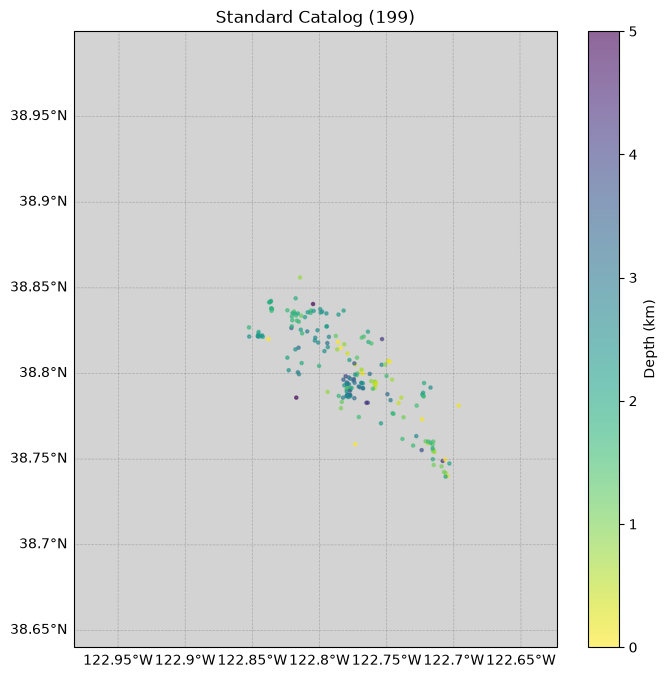

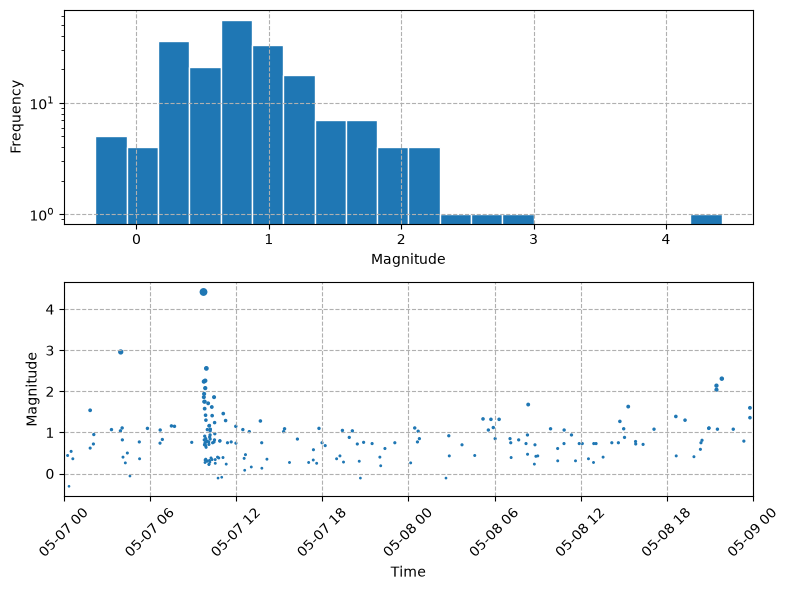

In [6]:
standard_catalog = download_catalog(region=region, config=config)
plot_catalog(standard_catalog, method="Standard", config=config)

### Download stations

In [7]:
def download_station(root_path: str = "local", region: str = "demo", config: Dict = {}):

    result_dir = f"{region}/obspy"
    if not os.path.exists(f"{root_path}/{result_dir}"):
        os.makedirs(f"{root_path}/{result_dir}")
    if not os.path.exists(f"{root_path}/{result_dir}/inventory/"):
        os.makedirs(f"{root_path}/{result_dir}/inventory/")

    ## Download stations
    stations = obspy.core.inventory.Inventory()
    for provider in config["provider"]:
        client = obspy.clients.fdsn.Client(provider)
        stations += client.get_stations(
                network=config["network"],
                station="*",
                starttime=config["starttime"],
                endtime=config["endtime"],
                latitude=config["latitude0"],
                longitude=config["longitude0"],
                maxradius=config["maxradius_degree"],
                channel=config["channel"],
                level="response",
            )
    stations.write(f"{root_path}/{result_dir}/inventory.xml", format="STATIONXML")
    print("Number of stations: {}".format(sum([len(x) for x in stations])))

    ## Save stations
    station_dict = defaultdict(dict)
    for network in stations:
        for station in network:
            inv = stations.select(network=network.code, station=station.code)
            inv.write(f"{root_path}/{result_dir}/inventory/{network.code}.{station.code}.xml", format="STATIONXML")
            for channel in station:
                sid = f"{network.code}.{station.code}.{channel.location_code}.{channel.code}"
                station_dict[sid] = {
                    "network": network.code,
                    "station": station.code,
                    "location": channel.location_code,
                    "channel": channel.code,
                    "longitude": channel.longitude,
                    "latitude": channel.latitude,
                    "elevation_m": channel.elevation,
                    "response": round(channel.response.instrument_sensitivity.value, 2),
                }

    # with open(f"{root_path}/{result_dir}/stations.json", "w") as fp:
    #     json.dump(station_dict, fp, indent=2)

    with open(f"{root_path}/{result_dir}/stations.pkl", "wb") as fp:
        pickle.dump(stations, fp)

    stations = pd.DataFrame.from_dict(station_dict, orient="index")
    stations.to_csv(f"{root_path}/{result_dir}/stations.csv", index=False)
        
    return stations

Number of stations: 70


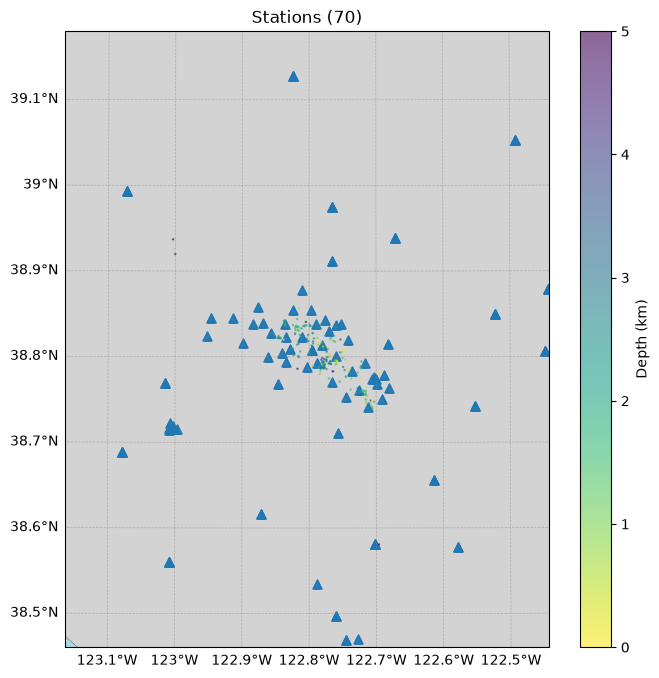

In [8]:
stations = download_station(region=region, config=config)
plot_stations(stations, catalog = standard_catalog, region=region, config=config)

### Download waveform data

In [9]:
from concurrent.futures import ThreadPoolExecutor

def map_remote_path(provider, bucket, starttime, network, station, location, channel):

    starttime = pd.Timestamp(starttime).round("h").to_pydatetime()  # in case of 2021-01-01T23:59:xxx
    if provider.lower() == "scedc":
        year = starttime.strftime("%Y")
        dayofyear = starttime.strftime("%j")
        if location == "":
            location = "__"
        path = f"s3://{bucket}/{year}/{year}_{dayofyear}/{network}{station:_<5}{channel}{location:_<2}_{year}{dayofyear}.ms"
    elif provider.lower() == "ncedc":
        year = starttime.strftime("%Y")
        dayofyear = starttime.strftime("%j")
        path = f"s3://{bucket}/{network}/{year}/{year}.{dayofyear}/{station}.{network}.{channel}.{location}.D.{year}.{dayofyear}"
    else:
        raise ValueError(f"Unknown provider: {provider}")
    return path

def download_waveform(root_path: str = "local", region: str = "demo", config: Dict = {}):

    waveform_dir = f"{region}/waveforms"
    if not os.path.exists(f"{root_path}/{waveform_dir}"):
        os.makedirs(f"{root_path}/{waveform_dir}")
    # print(json.dumps(config, indent=4))

    ## Download from cloud
    for provider in config["provider"]:
        if provider.lower() in ["scedc", "ncedc"]:
            cloud = {
                "provider": provider.lower(),
                "bucket": f"{provider.lower()}-pds/continuous_waveforms",
            }
        else:
            continue

        DELTATIME = "1D"
        starttime = datetime.fromisoformat(config["starttime"]).strftime("%Y-%m-%d")
        starttimes = pd.date_range(starttime, config["endtime"], freq=DELTATIME, tz="UTC", inclusive="left").to_list()
        # with open(f'{root_path}/{region}/obspy/stations.json', 'r') as f:
        #     stations = json.load(f)
        stations = pd.read_csv(f"{root_path}/{region}/obspy/stations.csv", na_filter=False)
        stations["instrument"] = stations['channel'].apply(lambda x: x[:-1])
        stations["component"] = stations['channel'].apply(lambda x: x[-1])
        location_priorities = ('', '00', '10', '01', '20', '02', '30', '03', '40', '04', 
                              '50', '05', '60', '06', '70', '07', '80', '08', '90', '09')
        location_priority_map = {loc: i for i, loc in enumerate(location_priorities)}
        instrument_priorities = ('HH', 'BH', 'MH', 'EH', 'LH', 'HL', 'BL', 'ML', 'EL', 'LL', 'SH')
        instrument_priority_map = {ch: i for i, ch in enumerate(instrument_priorities)}
        component_priorities = ('E', 'N', 'Z', '1', '2', '3')
        component_priority_map = {ch: i for i, ch in enumerate(component_priorities)}
        stations['location_priority'] = stations['location'].map(location_priority_map)
        stations['instrument_priority'] = stations['instrument'].apply(lambda x: instrument_priority_map.get(x, len(instrument_priorities)))
        stations['component_priority'] = stations['component'].apply(lambda x: component_priority_map.get(x, len(component_priorities)))
        stations.sort_values(['network', 'station', 'location_priority', 'instrument_priority', "component_priority"], inplace=True)
        stations.drop(['location_priority', 'instrument_priority', 'component_priority'], axis=1, inplace=True)

        def download_station(starttime, station):
            """One station-day: the first instrument (in priority order) with three components on the bucket."""
            prev = ""
            nch = set()
            for _, row in station.iterrows():
                if len(nch) >= 3:
                    break
                network, station, location, channel, instrument = row["network"], row["station"], row["location"], row["channel"], row["instrument"]
                if instrument != prev:
                    prev = instrument
                    nch = set()
                mseed_path = map_remote_path(
                    cloud["provider"],
                    cloud["bucket"],
                    starttime,
                    network,
                    station,
                    location,
                    channel,
                )
                try:
                    if os.path.exists(f"{root_path}/{waveform_dir}/{starttime.strftime('%Y/%j')}/{network}.{station}.{location}.{channel}.mseed"):
                        # print(f"{root_path}/{waveform_dir}/{starttime.strftime('%Y/%j')}/{network}.{station}.{location}.{channel}.mseed downloaded.")
                        nch.add(channel[-1])
                        continue
                    os.makedirs(f"{root_path}/{waveform_dir}/{starttime.strftime('%Y/%j')}", exist_ok=True)
                    with fsspec.open(f"{mseed_path}", "rb", s3={"anon": True}) as f:
                        data = f.read()
                    with open(f"{root_path}/{waveform_dir}/{starttime.strftime('%Y/%j')}/{network}.{station}.{location}.{channel}.mseed", "wb") as f:
                        f.write(data)
                        nch.add(channel[-1])
                except Exception as e:
                    # print(f"Failed to download {e}")
                    pass

        ## one station-day per thread: a single S3 stream is slow far from the bucket (us-west-2), 16 in parallel are ~10x faster
        tasks = [(starttime, station) for starttime in starttimes for _, station in stations.groupby(["network", "station"])]
        with ThreadPoolExecutor(max_workers=16) as pool:
            list(tqdm(pool.map(lambda x: download_station(*x), tasks), total=len(tasks), desc=f"Downloading from {cloud['provider']}"))

    # %% Download from FDSN
    domain = CircularDomain(
        longitude=config["longitude0"],
        latitude=config["latitude0"],
        minradius=0,
        maxradius=config["maxradius_degree"],
    )

    restrictions = Restrictions(
        starttime=obspy.UTCDateTime(config["starttime"]),
        endtime=obspy.UTCDateTime(config["endtime"]),
        chunklength_in_sec=3600 * 24, # 1 day
        network=config["network"] if "network" in config else None,
        station=config["station"] if "station" in config else None,
        minimum_interstation_distance_in_m=0,
        minimum_length=0.1,
        reject_channels_with_gaps=False,
    )

    def get_mseed_storage(network, station, location, channel, starttime, endtime):
        mseed_name = f"{starttime.strftime('%Y/%j')}/{network}.{station}.{location}.{channel}.mseed"
        if os.path.exists(f"{root_path}/{waveform_dir}/{mseed_name}"):
            # print(f"{root_path}/{waveform_dir}/{mseed_name} downloaded.")
            return True
        return f"{root_path}/{waveform_dir}/{mseed_name}"

    mdl = MassDownloader(
        providers=config["provider"],
        # providers=["IRIS"],
    )
    mdl.download(
        domain,
        restrictions,
        mseed_storage=get_mseed_storage,
        stationxml_storage=f"{root_path}/{waveform_dir}/stations",
        download_chunk_size_in_mb=20,
        threads_per_client=3,
        print_report=False,
    )
    
    return


In [10]:
download_waveform(region=region, config=config)

### Run PhaseNet-Plus to pick P/S picks

<!-- <img src="https://raw.githubusercontent.com/zhuwq0/images/main/202504062345927.png" style="width:50%;"> -->

![](https://raw.githubusercontent.com/zhuwq0/images/main/202504062345927.png)

PhaseNet-Plus: PhaseNet in PyTorch, trained on The Geysers; each P pick also carries its first-motion polarity in [-1, 1] (+ up, - down).

In [11]:
import torch
from phasenet.data.preprocess import merge_stream, resample_trace, orient_from_inventory, highpass
from phasenet.utils.inference import load_checkpoint, predict_2d, detect_picks

MODEL_URL = "https://github.com/AI4EPS/models/releases/download/PhaseNet-Plus-Geysers-v2/phasenet_plus_geysers_v2.pth"

def read_day(files, inv, t0, fs=100.0):
    """One station-instrument's day: (3, nt) velocity in m/s, components E, N, Z, zeros where data are missing;
    the station id; and z_sign, -1 where the archive's vertical points down (the model sees the archive's sign)."""
    nt = int(86400 * fs)
    st = obspy.Stream()
    for f in files:
        st += obspy.read(f)
    st.remove_sensitivity(inv)
    merge_stream(st)
    for tr in st:
        resample_trace(tr, fs)
    st = orient_from_inventory(st, inv)
    x = np.zeros((3, nt), dtype=np.float32)
    z_sign = 1
    for tr in st:
        k = "ENZ".index(tr.stats.channel[-1])
        tr.trim(t0, t0 + 86400, pad=True, fill_value=0.0, nearest_sample=True)
        d = np.asarray(tr.data, dtype=np.float64)[:nt]
        if k == 2:
            d = d * tr.stats.z_sign
            z_sign = tr.stats.z_sign
        if tr.stats.channel[1] == "N":  # accelerometer: integrate to velocity
            d = np.cumsum(d) / fs
        x[k, : len(d)] = d
    return highpass(x, 1.0, fs).astype(np.float32), f"{st[0].stats.network}.{st[0].stats.station}.{st[0].stats.location}.{st[0].stats.channel[:-1]}", z_sign

def pick_amplitude(amp, picks, fs=100.0, window_s=12.0):
    """Peak 3-component amplitude from each pick to the next pick of the same phase, at most window_s (as PhaseNet)."""
    out = np.full(len(picks), -1.0)
    for _, g in picks.groupby("phase_type"):
        idx = g.phase_index.to_numpy()
        nxt = np.append(idx[1:], len(amp))
        for j, (i0, i1) in enumerate(zip(idx, np.minimum(nxt, idx + int(window_s * fs)))):
            out[g.index[j]] = amp[i0:max(i1, i0 + 1)].max()
    return out

def run_phasenet_plus(root_path: str = "local", region: str = "demo", config: Dict = {}, min_prob: float = 0.3,
                      batch_size: int = 64) -> str:

    result_path = f"{region}/phasenet"
    os.makedirs(f"{root_path}/{result_path}", exist_ok=True)
    device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
    os.makedirs(f"{root_path}/model", exist_ok=True)
    model_file = f"{root_path}/model/phasenet_plus_geysers_v2.pth"
    if not os.path.exists(model_file):
        torch.hub.download_url_to_file(MODEL_URL, model_file)
    model = load_checkpoint(model_file, device=device)
    inv = obspy.read_inventory(f"{root_path}/{region}/obspy/inventory.xml")
    fs = 100.0

    all_picks = []
    for day_dir in sorted(glob(f"{root_path}/{region}/waveforms/????/???")):
        t0 = obspy.UTCDateTime(datetime.strptime(day_dir[-8:], "%Y/%j"))
        ## group 3C channels: one row per station-instrument (e.g. CI.CCC..HH)
        groups = sorted({x.split(".mseed")[0][:-1] for x in glob(f"{day_dir}/*.mseed")})
        ## a model that picks each station on its own (window_nx = 1, as this one) gets one station-day per call, so memory
        ## stays at one station; a model that looks across stations gets them all, cut into its patches by predict_2d
        groups = [[g] for g in groups] if model.input.window_nx == 1 else [groups]
        read = lambda group: [read_day(glob(g + "*.mseed"), inv, t0, fs) for g in group]
        ## read the next station-day on the CPU while the GPU picks this one; one reader, since obspy's merge is not thread-safe
        with ThreadPoolExecutor(max_workers=1) as pool:
            ahead = pool.submit(read, groups[0])
            for k, group in enumerate(tqdm(groups, desc=f"Pick {day_dir[-8:]}")):
                rows = ahead.result()
                if k + 1 < len(groups):
                    ahead = pool.submit(read, groups[k + 1])
                x = np.stack([r[0] for r in rows], axis=1)  # (3, stations, nt)
                ## 4096-sample windows overlapping by half, batch_size windows per forward pass
                out = predict_2d(model, x, device=device, max_batch_size=batch_size)
                scores = out[0] if isinstance(out, tuple) else out  # (4, stations, nt): noise, P, S, P(up)
                for i, (_, station_id, z_sign) in enumerate(rows):
                    p = pd.DataFrame(detect_picks(scores[:, i:i + 1], [station_id], {}, None, dt_s=1 / fs, vmin=min_prob, id_key="station_id"))
                    if len(p) == 0:
                        continue
                    p = p.sort_values(["phase_type", "phase_index"]).reset_index(drop=True)
                    p["z_sign"] = z_sign
                    p["phase_amplitude"] = pick_amplitude(np.abs(x[:, i]).max(axis=0), p, fs)
                    p["phase_time"] = [(t0 + j / fs).strftime("%Y-%m-%dT%H:%M:%S.%f")[:23] for j in p.phase_index]
                    all_picks.append(p)

    picks = pd.concat(all_picks, ignore_index=True)
    ## phase_polarity: on P picks, the first-motion polarity in [-1, 1] (+ up, - down; |value| its weight); empty on S picks
    picks = picks[["station_id", "phase_index", "phase_time", "phase_score", "phase_type", "phase_amplitude", "phase_polarity", "z_sign"]].sort_values("phase_time")
    picks.to_csv(f"{root_path}/{result_path}/phasenet_picks.csv", index=False)
    print(f"Done with {sum(picks.phase_type == 'P')} P-picks and {sum(picks.phase_type == 'S')} S-picks")

    return f"{root_path}/{result_path}/phasenet_picks.csv"


In [12]:
phasenet_picks = run_phasenet_plus(region=region, config=config)

Done with 28310 P-picks and 27216 S-picks


### Run GaMMA to associate P/S picks

<!-- <img src="https://raw.githubusercontent.com/zhuwq0/images/main/202504062233284.png" style="width:50%;"> -->

![](https://raw.githubusercontent.com/zhuwq0/images/main/202504062233284.png)

In [13]:
def run_gamma(root_path: str = "local", region: str = "demo", config: Dict = {}):

    data_path = f"{region}/phasenet"
    result_path = f"{region}/gamma"
    if not os.path.exists(f"{root_path}/{result_path}"):
        os.makedirs(f"{root_path}/{result_path}")

    picks_csv = f"{data_path}/phasenet_picks.csv"
    gamma_events_csv = f"{result_path}/gamma_events.csv"
    gamma_picks_csv = f"{result_path}/gamma_picks.csv"

    ## read picks: GaMMA uses PhaseNet's columns (station_id, phase_time, phase_type, phase_score, phase_amplitude)
    picks = pd.read_csv(f"{root_path}/{picks_csv}")
    picks.drop(columns=["event_index"], inplace=True, errors="ignore")

    ## read stations
    stations = pd.read_csv(f"{root_path}/{region}/obspy/stations.csv", na_filter=False)
    stations["station_id"] = stations.apply(lambda x: f"{x['network']}.{x['station']}.{x['location']}.{x['channel'][:-1]}", axis=1)
    stations = stations.groupby("station_id").agg(lambda x: x.iloc[0] if len(set(x)) == 1 else sorted(list(x))).reset_index()
    proj = Proj(f"+proj=aeqd +lon_0={config['longitude0']} +lat_0={config['latitude0']} +units=km")
    stations[["x_km", "y_km"]] = stations.apply(
        lambda x: pd.Series(proj(longitude=x.longitude, latitude=x.latitude)), axis=1
    )
    stations["z_km"] = stations["elevation_m"].apply(lambda x: -x / 1e3)

    ## setting GaMMA configs
    config["segment"] = "dbscan"  # cut the picks into groups for the mixture by DBSCAN in time and space
    config["use_amplitude"] = True
    config["method"] = "BGMM"
    if config["method"] == "BGMM":  ## BayesianGaussianMixture
        config["oversample_factor"] = 5
    if config["method"] == "GMM":  ## GaussianMixture
        config["oversample_factor"] = 1

    # earthquake location
    config["vel"] = {"P": 6.0, "S": 6.0 / 1.75}
    config["dims"] = ["x_km", "y_km", "z_km"]
    minlat, maxlat = config["latitude0"] - config["maxradius_degree"], config["latitude0"] + config["maxradius_degree"]
    minlon, maxlon = config["longitude0"] - config["maxradius_degree"], config["longitude0"] + config["maxradius_degree"]
    xmin, ymin = proj(minlon, minlat)
    xmax, ymax = proj(maxlon, maxlat)
    zmin = config["mindepth"] if "mindepth" in config else 0
    zmax = config["maxdepth"] if "maxdepth" in config else 30
    config["xlim_km"] = (xmin, xmax)
    config["ylim_km"] = (ymin, ymax)
    config["zlim_km"] = (zmin, zmax)
    config["bfgs_bounds"] = (
        (config["xlim_km"][0] - 1, config["xlim_km"][1] + 1),  # x
        (config["ylim_km"][0] - 1, config["ylim_km"][1] + 1),  # y
        (0, config["zlim_km"][1] + 1),  # z
        (None, None),  # t
    )

    # DBSCAN
    config["dbscan_eps"] = estimate_eps(stations, config["vel"]["P"])  # s
    config["dbscan_min_samples"] = 3

    ## Eikonal for 1D velocity model
    zz = [0.0, 5.5, 5.5, 16.0, 16.0, 32.0, 32.0]
    vp = [5.5, 5.5, 6.3, 6.3, 6.7, 6.7, 7.8]
    vp_vs_ratio = 1.73
    vs = [v / vp_vs_ratio for v in vp]
    h = 0.3
    vel = {"Z": zz, "P": vp, "S": vs}
    config["eikonal"] = {"vel": vel, "h": h, "xlim_km": config["xlim_km"], "ylim_km": config["ylim_km"], "zlim_km": config["zlim_km"]}

    # filtering
    config["min_picks"] = 5
    config["min_p_picks"] = 0
    config["min_s_picks"] = 0
    config["max_residual_time"] = 2.0  # s, after each event is relocated
    config["max_residual_amplitude"] = 1.0  # log10(m/s)

    ## filter picks without amplitude measurements
    if config["use_amplitude"]:
        picks = picks[picks["phase_amplitude"] != -1]

    print(f"Number of picks: {len(picks)}")

    # %%
    event_idx0 = 0  ## current earthquake index
    events, assignments = association(picks, stations, config, event_idx0, config["method"])

    if len(events) == 0:
        return 
    
    ## create catalog
    events = pd.DataFrame(events)
    events[["longitude", "latitude"]] = events.apply(
        lambda x: pd.Series(proj(longitude=x["x_km"], latitude=x["y_km"], inverse=True)), axis=1
    )
    events.sort_values("time", inplace=True)
    with open(f"{root_path}/{gamma_events_csv}", "w") as fp:
        events.to_csv(fp, index=False, float_format="%.3f", date_format="%Y-%m-%dT%H:%M:%S.%f")
    ## add assignment to picks
    assignments = pd.DataFrame(assignments, columns=["pick_index", "event_index", "gamma_score"])
    picks = picks.join(assignments.set_index("pick_index")).fillna(-1).astype({"event_index": int})
    picks.sort_values(["phase_time"], inplace=True)
    with open(f"{root_path}/{gamma_picks_csv}", "w") as fp:
        picks.to_csv(fp, index=False, date_format="%Y-%m-%dT%H:%M:%S.%f")

    return events


In [14]:
gamma_catalog = run_gamma(region=region, config=config)

Number of picks: 55526


Eikonal: 14 station tables of 341 x 44 nodes in 0.7 s


Associated 1177 events with 38568 picks


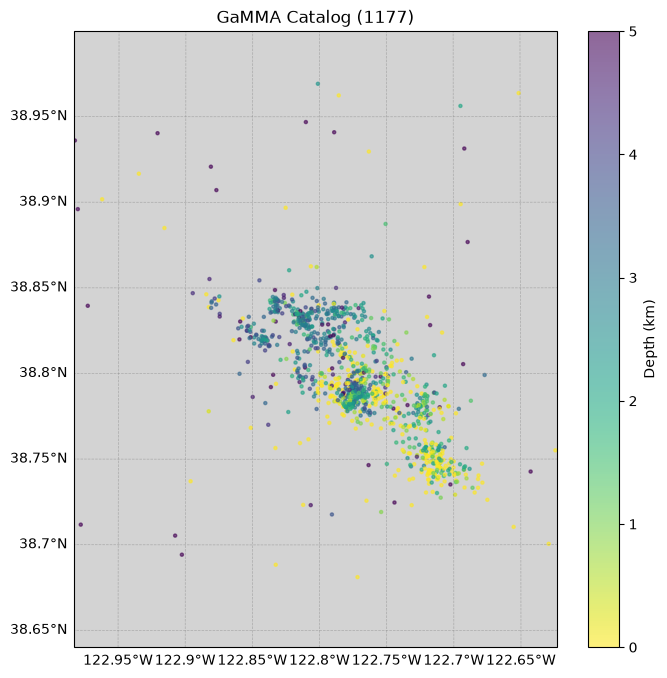

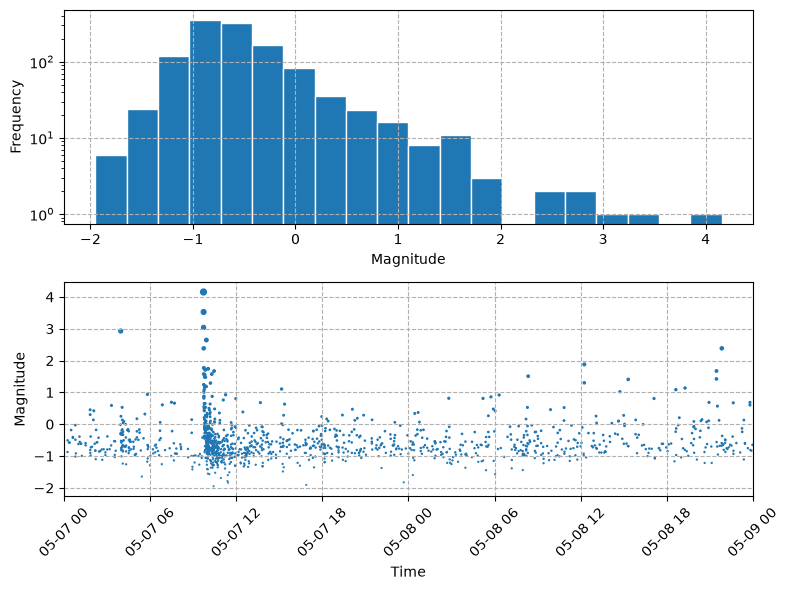

In [15]:
plot_catalog(gamma_catalog, "GaMMA", region=region, config=config)

### Run ADLoc to locate absolute earthquake locations

<!-- <img src="https://raw.githubusercontent.com/zhuwq0/images/main/202504062236724.png" style="width:50%;"> -->

![](https://raw.githubusercontent.com/zhuwq0/images/main/202504062236724.png)

In [16]:
def run_adloc(root_path: str = "local", region: str = "demo", config: Dict = {}):

    data_path = f"{root_path}/{region}/gamma"
    result_path = f"{root_path}/{region}/adloc"
    figure_path = f"{root_path}/{region}/adloc/figures"
    if not os.path.exists(result_path):
        os.makedirs(result_path)
    if not os.path.exists(figure_path):
        os.makedirs(figure_path)

    picks_file = f"{data_path}/gamma_picks.csv"
    events_file = f"{data_path}/gamma_events.csv"
    stations_file = f"{root_path}/{region}/obspy/stations.csv"

    proj = Proj(f"+proj=aeqd +lon_0={config['longitude0']} +lat_0={config['latitude0']}  +units=km")
    config["proj"] = proj  # ADLoc >= 1.0.5 locates in this frame, from the GaMMA locations; without it the catalogue shifts

    ## read picks and associated events
    picks = pd.read_csv(picks_file)
    picks["phase_time"] = pd.to_datetime(picks["phase_time"])
     # drop unnecessary columns
    picks.drop(["id", "timestamp", "type", "amp", "prob", "event_idx"], axis=1, inplace=True, errors="ignore")
    if os.path.exists(events_file):
        events = pd.read_csv(events_file)
        events["time"] = pd.to_datetime(events["time"])
        events[["x_km", "y_km"]] = events.apply(
            lambda x: pd.Series(proj(longitude=x.longitude, latitude=x.latitude)), axis=1
        )
        events["z_km"] = events["depth_km"] if "depth_km" in events.columns else 10.0
    else:
        events = None

    ## read stations
    # stations = pd.read_json(stations_file, orient="index")
    stations = pd.read_csv(stations_file, na_filter=False)
    stations["station_id"] = stations.apply(lambda x: f"{x['network']}.{x['station']}.{x['location']}.{x['channel'][:-1]}", axis=1)
    stations = stations.groupby("station_id").agg(lambda x: x.iloc[0] if len(set(x)) == 1 else sorted(list(x))).reset_index()
    stations["depth_km"] = -stations["elevation_m"] / 1000
    if "station_term_time_p" not in stations.columns:
        stations["station_term_time_p"] = 0.0
    if "station_term_time_s" not in stations.columns:
        stations["station_term_time_s"] = 0.0
    if "station_term_amplitude" not in stations.columns:
        stations["station_term_amplitude"] = 0.0
    stations[["x_km", "y_km"]] = stations.apply(
        lambda x: pd.Series(proj(longitude=x.longitude, latitude=x.latitude)), axis=1
    )
    stations["z_km"] = stations["elevation_m"].apply(lambda x: -x / 1e3)

    ## setting ADLoc configs
    config["use_amplitude"] = False  # amplitudes still give the magnitude; True also rejects events by them (GaMMA sets it True above)

    minlat, maxlat = config["latitude0"] - config["maxradius_degree"], config["latitude0"] + config["maxradius_degree"]
    minlon, maxlon = config["longitude0"] - config["maxradius_degree"], config["longitude0"] + config["maxradius_degree"]
    xmin, ymin = proj(minlon, minlat)
    xmax, ymax = proj(maxlon, maxlat)
    zmin, zmax = min(config["mindepth"], stations["z_km"].min()), config["maxdepth"]  # depth (km below sea level) may go up to the highest station, not above the ground
    config["xlim_km"] = (xmin, xmax)
    config["ylim_km"] = (ymin, ymax)
    config["zlim_km"] = (zmin, zmax)

    ## Eikonal for 1D velocity model
    # NCSN Geysers (gey.crh, Eberhart-Phillips & Oppenheimer, 1984), as constant layers
    zz = [0.0, 1.5, 1.5, 3.0, 3.0, 4.25, 4.25, 6.0, 6.0, 8.0, 8.0, 21.0, 21.0, 60.0]
    vp = [4.43, 4.43, 5.12, 5.12, 5.47, 5.47, 5.58, 5.58, 5.62, 5.62, 5.86, 5.86, 7.90, 7.90]
    vp_vs_ratio = 1.73
    vs = [v / vp_vs_ratio for v in vp]
    # Northern California (Gil7)
    # zz = [0.0, 1.0, 3.0, 4.0, 5.0, 17.0, 25.0, 62.0]
    # vp = [3.2, 3.2, 4.5, 4.8, 5.51, 6.21, 6.89, 7.83]
    # vs = [1.5, 1.5, 2.4, 2.78, 3.18, 3.40, 3.98, 4.52]
    h = 0.3
    vel = {"Z": zz, "P": vp, "S": vs}
    config["eikonal"] = {
        "vel": vel,
        "h": h,
        "xlim_km": config["xlim_km"],
        "ylim_km": config["ylim_km"],
        "zlim_km": config["zlim_km"],
        "station_z_km": stations["z_km"].values,  # one travel-time table per station elevation
    }
    config["eikonal"] = init_eikonal2d(config["eikonal"])

    # RASAC
    config["min_picks"] = 6
    config["min_picks_ratio"] = 0.5
    config["max_residual_time"] = 1.0
    config["max_residual_amplitude"] = 1.0
    config["min_score"] = 0.5
    config["min_s_picks"] = 1.5
    config["min_p_picks"] = 1.5

    config["bfgs_bounds"] = (
        (config["xlim_km"][0] - 1, config["xlim_km"][1] + 1),  # x
        (config["ylim_km"][0] - 1, config["ylim_km"][1] + 1),  # y
        (config["zlim_km"][0], config["zlim_km"][1] + 1),  # z: from the highest station
        (None, None),  # t
    )

    # %%
    mapping_phase_type_int = {"P": 0, "S": 1}
    picks["phase_type"] = picks["phase_type"].map(mapping_phase_type_int)
    if "phase_amplitude" in picks.columns:
        picks["phase_amplitude"] = picks["phase_amplitude"].apply(lambda x: np.log10(x) + 2.0)  # convert to log10(cm/s)

    # %%
    stations["idx_sta"] = np.arange(len(stations))
    if events is None:
        picks = picks.merge(stations[["station_id", "x_km", "y_km", "z_km"]], on="station_id")
        events = picks.groupby("event_index").agg({"x_km": "mean", "y_km": "mean", "z_km": "mean", "phase_time": "min"})
        events["z_km"] = 10.0  # km default depth
        events.rename({"phase_time": "time"}, axis=1, inplace=True)
        events["event_index"] = events.index
        events.reset_index(drop=True, inplace=True)
        events["idx_eve"] = np.arange(len(events))
        picks.drop(["x_km", "y_km", "z_km"], axis=1, inplace=True)
    else:
        events["idx_eve"] = np.arange(len(events))

    picks = picks.merge(events[["event_index", "idx_eve"]], on="event_index")
    picks = picks.merge(stations[["station_id", "idx_sta"]], on="station_id")


    # for key, value in config.items():
    #     print(f"{key}: {value}")

    print(f"Number of picks: {len(picks)}")
    print(f"Number of events: {len(events)}")

    # %%
    estimator = ADLoc(config, eikonal=config["eikonal"])

    # %%
    MAX_SST_ITER = 8
    events_init = events.copy()

    for iter in range(MAX_SST_ITER):
        picks, events = invert_location(picks, stations, config, estimator, events_init=events_init, iter=iter)

        station_term_amp = (
            picks[picks["mask"] == 1.0].groupby("idx_sta").agg({"residual_amplitude": "median"}).reset_index()
        )
        station_term_amp.set_index("idx_sta", inplace=True)
        stations["station_term_amplitude"] += stations["idx_sta"].map(station_term_amp["residual_amplitude"]).fillna(0)

        station_term_time = (
            picks[picks["mask"] == 1.0].groupby(["idx_sta", "phase_type"]).agg({"residual_time": "mean"}).reset_index()
        )
        station_term_time.set_index("idx_sta", inplace=True)
        stations["station_term_time_p"] += (
            stations["idx_sta"].map(station_term_time[station_term_time["phase_type"] == 0]["residual_time"]).fillna(0)
        )
        stations["station_term_time_s"] += (
            stations["idx_sta"].map(station_term_time[station_term_time["phase_type"] == 1]["residual_time"]).fillna(0)
        )

        if "event_index" not in events.columns:
            events["event_index"] = events.merge(picks[["idx_eve", "event_index"]], on="idx_eve")["event_index"]
        events[["longitude", "latitude"]] = events.apply(
            lambda x: pd.Series(proj(x["x_km"], x["y_km"], inverse=True)), axis=1
        )
        events["depth_km"] = events["z_km"]

        picks["adloc_mask"] = picks["mask"]
        picks["adloc_residual_time"] = picks["residual_time"]
        picks["adloc_residual_amplitude"] = picks["residual_amplitude"]

        picks.to_csv(os.path.join(result_path, f"adloc_picks_sst_{iter}.csv"), index=False)
        events.to_csv(os.path.join(result_path, f"adloc_events_sst_{iter}.csv"), index=False)
        stations.to_csv(os.path.join(result_path, f"adloc_stations_sst_{iter}.csv"), index=False)

    # %%
    if "event_index" not in events.columns:
        events["event_index"] = events.merge(picks[["idx_eve", "event_index"]], on="idx_eve")["event_index"]
    events[["longitude", "latitude"]] = events.apply(
        lambda x: pd.Series(proj(x["x_km"], x["y_km"], inverse=True)), axis=1
    )
    events["depth_km"] = events["z_km"]
    events.drop(["idx_eve", "x_km", "y_km", "z_km"], axis=1, inplace=True, errors="ignore")
    events.sort_values(["time"], inplace=True)

    picks["phase_type"] = picks["phase_type"].map({0: "P", 1: "S"})
    picks.drop(
        ["idx_eve", "idx_sta", "mask", "residual_time", "residual_amplitude"], axis=1, inplace=True, errors="ignore"
    )
    picks.sort_values(["phase_time"], inplace=True)

    stations.drop(["idx_sta", "x_km", "y_km", "z_km"], axis=1, inplace=True, errors="ignore")

    picks.to_csv(os.path.join(result_path, "adloc_picks.csv"), index=False)
    events.to_csv(os.path.join(result_path, "adloc_events.csv"), index=False)
    stations.to_csv(os.path.join(result_path, "adloc_stations.csv"), index=False)

    return events

In [17]:
adloc_catalog = run_adloc(region=region, config=config)

Eikonal: 14 station tables of 341 x 44 nodes in 0.4 s
Number of picks: 38568
Number of events: 1177
Using 15 CPUs for ADLoc inversion.


ADLoc locates 1005 events outof 1177 events
using 37184 picks outof 38568 picks


Using 15 CPUs for ADLoc inversion.


ADLoc locates 1004 events outof 1177 events
using 37203 picks outof 38568 picks


Using 15 CPUs for ADLoc inversion.


ADLoc locates 1004 events outof 1177 events
using 37199 picks outof 38568 picks


... (6 outputs left out)

Using 15 CPUs for ADLoc inversion.


ADLoc locates 1005 events outof 1177 events
using 37209 picks outof 38568 picks


Using 15 CPUs for ADLoc inversion.


ADLoc locates 1005 events outof 1177 events
using 37210 picks outof 38568 picks


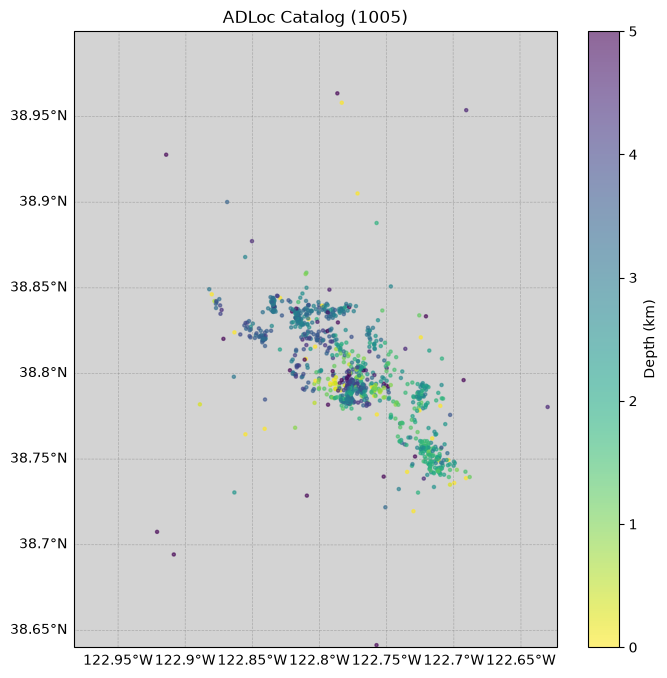

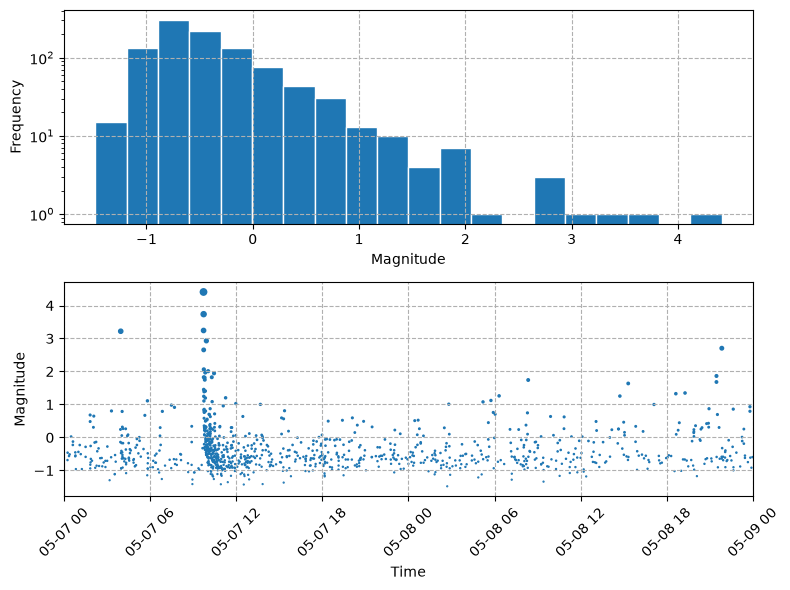

In [18]:
plot_catalog(adloc_catalog, "ADLoc", region=region, config=config)

### Run HyperDD to relocate relative earthquake locations

<!-- <img src="https://raw.githubusercontent.com/zhuwq0/images/main/202504062239659.png" style="width:40%;">
<br>
<img src="https://raw.githubusercontent.com/zhuwq0/images/main/202504062241134.png" style="width:30%;"> -->

![](https://raw.githubusercontent.com/zhuwq0/images/main/202504062239659.png)

![](https://raw.githubusercontent.com/zhuwq0/images/main/202504062241134.png)

Credit: Felix Waldhauser

In [19]:
import contextlib, io
from hyperdd.io.ph2dt import ph2dt
from hyperdd.io.inputs import write_hypodd_inputs, ITER_SETS_CT
from hyperdd.hypoDD import run_hypoDD


def run_hyperdd(root_path: str = "local", region: str = "demo", mu: float = 0.1) -> pd.DataFrame:

    result_path = f"{root_path}/{region}/hyperdd"
    os.makedirs(result_path, exist_ok=True)

    ## ADLoc's events, stations and the picks it kept; HypoDD names a station by its code, depths are km below sea level
    events = pd.read_csv(f"{root_path}/{region}/adloc/adloc_events.csv", parse_dates=["time"]).rename(columns={"event_index": "event_id"})
    stations = pd.read_csv(f"{root_path}/{region}/adloc/adloc_stations.csv").drop_duplicates("station")
    picks = pd.read_csv(f"{root_path}/{region}/adloc/adloc_picks.csv", parse_dates=["phase_time"])
    picks = picks[picks["adloc_mask"] == 1].merge(events[["event_id", "time"]], left_on="event_index", right_on="event_id")
    picks["station"] = picks["station_id"].str.split(".").str[1]
    picks["travel_time"] = (picks["phase_time"] - picks["time"]).dt.total_seconds()
    picks = picks.sort_values("phase_score").drop_duplicates(["event_id", "station", "phase_type"], keep="last")  # one instrument per station

    ## Catalog differential times for pairs of nearby events at common stations (HypoDD's ph2dt)
    with contextlib.redirect_stdout(io.StringIO()):
        dt, _ = ph2dt(dict(id=events["event_id"].values, lat=events["latitude"].values, lon=events["longitude"].values, dep=events["depth_km"].values),
                      dict(event_id=picks["event_id"].values, station=picks["station"].values, time=picks["travel_time"].values,
                           weight=picks["phase_score"].values, phase=picks["phase_type"].values),
                      dict(station=stations["station"].values, lat=stations["latitude"].values, lon=stations["longitude"].values),
                      maxdist=200, maxsep=10, maxngh=20, limobs_pair=8, minobs_pair=8, maxobs_pair=50, as_frame=True)
    print(f"{len(dt)} differential times on {len(dt.groupby(['id1', 'id2']))} event pairs")

    ## Relocate: stations at their elevations, events free to move above sea level (IAQ 2), damping mu, NCSN Geysers model (gey.crh)
    tops = [0.0, 1.5, 3.0, 4.25, 6.0, 8.0, 21.0]
    vp = [4.43, 5.12, 5.47, 5.58, 5.62, 5.86, 7.90]
    write_hypodd_inputs(result_path, events, stations, dt, (tops, vp, 1.73), damp=-mu, iter_sets=ITER_SETS_CT, iaq=2)
    cwd = os.getcwd(); os.chdir(result_path)
    try:
        with contextlib.redirect_stdout(io.StringIO()):  # HypoDD's iteration log
            run_hypoDD("hypoDD.inp", max_step_km=2.0)  # at most 2 km per event per iteration
    finally:
        os.chdir(cwd)

    ## Read the relocations
    columns = ["event_id", "latitude", "longitude", "depth_km", "x", "y", "z", "ex", "ey", "ez", "year", "month", "day", "hour", "minute", "second",
               "magnitude", "nccp", "nccs", "nctp", "ncts", "rcc", "rct", "cid"]
    catalog = pd.read_csv(f"{result_path}/hypoDD.reloc", sep=r"\s+", header=None, names=columns)
    catalog["time"] = pd.to_datetime(catalog[["year", "month", "day", "hour", "minute"]]) + pd.to_timedelta(catalog["second"], unit="s")
    catalog = catalog.merge(events[["event_id", "magnitude"]], on="event_id", suffixes=("_dd", ""))  # ADLoc's magnitude
    catalog = catalog[["event_id", "time", "latitude", "longitude", "depth_km", "magnitude"]]
    catalog.to_csv(f"{result_path}/hyperdd_catalog.csv", index=False)
    print(f"{len(catalog)} of {len(events)} events relocated")
    return catalog

In [20]:
hyperdd_catalog = run_hyperdd(region=region)

282656 differential times on 12875 event pairs


948 of 1005 events relocated


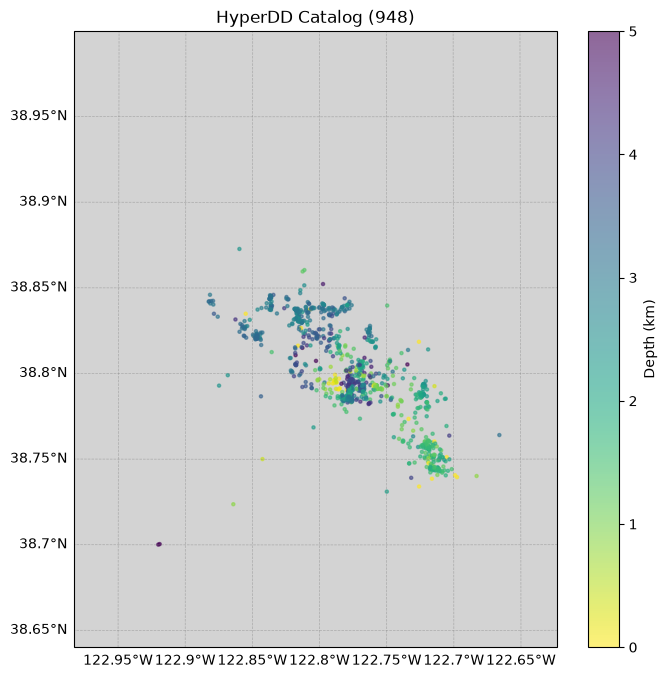

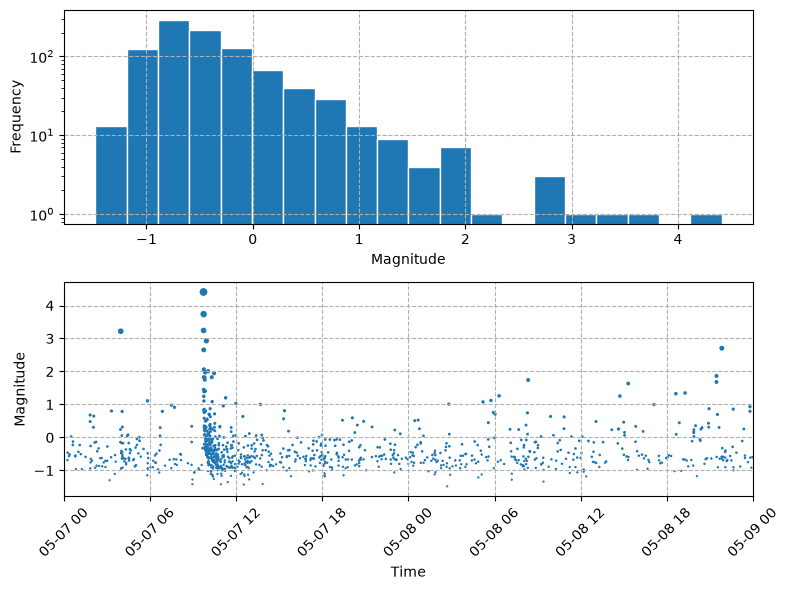

In [21]:
plot_catalog(hyperdd_catalog, "HyperDD", region=region, config=config)

### Run SKHASH to invert focal mechanisms from the P polarities

Polarity weight $w = s\,p$ ($p$: the pick's `phase_polarity`; $s$: the vertical's `z_sign`); take-off angles from ADLoc's travel-time tables.

In [22]:
from adloc.eikonal2d import traveltime_grad


def takeoff_azimuth(dx, dy, z, z_sta, eikonal):
    """Take-off angle (deg from vertical up; HASH's convention) and azimuth (deg from north, event to station) of the P ray,
    for events at offsets dx, dy (km, event - station) and depth z (km) from stations at depth z_sta, from ADLoc's tables."""
    _, grad = traveltime_grad(dx, dy, z, z_sta, 0, eikonal)  # (n, 3): dT/dx, dT/dy, dT/dz at the event
    takeoff = np.degrees(np.arccos(np.clip(grad[:, 2] / np.linalg.norm(grad, axis=1), -1, 1)))
    azimuth = np.degrees(np.arctan2(-dx, -dy)) % 360
    return takeoff, azimuth


def run_skhash(root_path: str = "local", region: str = "demo", config: Dict = {}, min_weight: float = 0.1) -> pd.DataFrame:

    result_path = f"{root_path}/{region}/skhash"
    for d in ("IN", "OUT"):
        os.makedirs(f"{result_path}/{d}", exist_ok=True)
    proj = Proj(f"+proj=aeqd +lon_0={config['longitude0']} +lat_0={config['latitude0']} +units=km")  # as ADLoc

    ## Catalog: every ADLoc event, also those above sea level
    events = pd.read_csv(f"{root_path}/{region}/adloc/adloc_events.csv", parse_dates=["time"])
    catalog = pd.DataFrame({"event_id": events["event_index"], "time": events["time"].dt.strftime("%Y-%m-%dT%H:%M:%S.%f"),
                            "latitude": events["latitude"], "longitude": events["longitude"], "depth": events["depth_km"],
                            "mag": events["magnitude"], "horz_uncert_km": 0.0, "vert_uncert_km": 0.0})
    catalog.to_csv(f"{result_path}/IN/catalog.csv", index=False)

    ## Polarities: the P picks ADLoc kept, one per event and station-instrument, as weights in [-1, 1]
    stations = pd.read_csv(f"{root_path}/{region}/adloc/adloc_stations.csv", dtype={"location": str})
    picks = pd.read_csv(f"{root_path}/{region}/adloc/adloc_picks.csv")
    picks = picks[(picks["phase_type"] == "P") & (picks["adloc_mask"] == 1)]
    picks = picks.sort_values("phase_score").drop_duplicates(["event_index", "station_id"], keep="last")
    picks = picks.merge(events[["event_index", "longitude", "latitude", "depth_km"]], on="event_index")
    picks = picks.merge(stations[["station_id", "network", "station", "location", "longitude", "latitude", "elevation_m"]], on="station_id", suffixes=("", "_sta"))
    picks["p_polarity"] = (picks["z_sign"] * picks["phase_polarity"]).round(3)

    ## Take-off angles and azimuths from ADLoc's tables (the same model, grid and station elevations as the locations)
    x, y = proj(picks["longitude"].values, picks["latitude"].values)
    x_sta, y_sta = proj(picks["longitude_sta"].values, picks["latitude_sta"].values)
    picks["takeoff"], picks["azimuth"] = takeoff_azimuth(x - x_sta, y - y_sta, picks["depth_km"].values, -picks["elevation_m"].values / 1e3, config["eikonal"])
    picks["sr_dist_km"] = np.hypot(x - x_sta, y - y_sta)
    picks["takeoff_uncertainty"], picks["azimuth_uncertainty"] = 0.0, 0.0  # the angles are taken as exact (no location errors yet)
    picks["location"] = picks["location"].fillna("").astype(str).replace("", "--")
    picks["channel"] = picks["station_id"].str.split(".").str[-1] + "Z"
    pol = picks.rename(columns={"event_index": "event_id"})[["event_id", "network", "station", "location", "channel", "p_polarity",
                                                              "takeoff", "takeoff_uncertainty", "azimuth", "azimuth_uncertainty", "sr_dist_km"]]
    ## SKHASH silently drops a polarity whose angles are missing, and reads take-off from up (0) to down (180)
    assert pol[["takeoff", "azimuth"]].notna().all().all() and pol["takeoff"].between(0, 180).all()
    pol.round(2).sort_values(["event_id", "network", "station"]).to_csv(f"{result_path}/IN/pol.csv", index=False)
    print(f"{len(pol)} P polarities on {pol.event_id.nunique()} events ({(events.depth_km < 0).sum()} events above sea level); "
          f"{(pol.p_polarity.abs() >= min_weight).mean():.0%} with |w| >= {min_weight}; {(pol.takeoff > 90).mean():.0%} of rays leave downward")

    ## No station file and no velocity model: SKHASH uses the angles as given and cannot recompute them
    control = {
        "catfile": f"{result_path}/IN/catalog.csv",
        "fpfile": f"{result_path}/IN/pol.csv",
        "outfile1": f"{result_path}/OUT/out.csv",
        "outfile_pol_agree": f"{result_path}/OUT/out_polagree.csv",
        "outfile_pol_info": f"{result_path}/OUT/out_polinfo.csv",
        "npolmin": 8,              # minimum number of polarities
        "min_polarity_weight": min_weight,
        "nmc": 30,                 # Monte Carlo trials over take-off angle and azimuth
        "maxout": 500,             # max acceptable mechanisms kept
        "badfrac": 0.1,            # fraction of polarities assumed wrong
        "delmax": 60,              # max source-receiver distance (km)
        "max_agap": 180,           # max azimuthal gap (deg)
        "max_pgap": 90,            # max take-off angle gap (deg)
        "cangle": 45,              # angle for the mechanism probability
        "prob_max": 0.2,           # probability threshold for multiple solutions
    }
    with open(f"{result_path}/control_file.txt", "w") as fp:
        fp.writelines(f"${k}\n{v}\n\n" for k, v in control.items())

    os.system(f"hashpy {result_path}/control_file.txt > {result_path}/skhash.log 2>&1")
    mechanisms = pd.read_csv(f"{result_path}/OUT/out.csv")
    best = mechanisms.drop_duplicates("event_id")  # one row per solution; the first is the preferred one
    print(f"{len(best)} events with a mechanism ({len(mechanisms)} solutions); quality {best['quality'].value_counts().sort_index().to_dict()}")
    return mechanisms


In [23]:
skhash_catalog = run_skhash(region=region, config=config)
skhash_catalog.head()

19033 P polarities on 1005 events (32 events above sea level); 70% with |w| >= 0.1; 15% of rays leave downward


598 events with a mechanism (861 solutions); quality {'A': 20, 'B': 71, 'C': 86, 'D': 421}


,event_id,strike,dip,rake,quality,fault_plane_uncertainty,aux_plane_uncertainty,num_p_pol,num_sp_ratios,azimuthal_gap,...,sta_distribution_ratio,sp_misfit,mult_solution_flag,time,magnitude,origin_lat,origin_lon,origin_depth_km,horz_uncert_km,vert_uncert_km
0,1,195.5,72.1,105.5,D,38.2,43.0,16,0,56.0,...,64.9,0.0,True,2026-05-07 00:14:24,-0.460659,38.835598,-122.793221,3.186385,0.0,0.0
1,1,44.0,82.4,-171.1,D,50.7,53.7,16,0,56.0,...,56.5,0.0,True,2026-05-07 00:14:24,-0.460659,38.835598,-122.793221,3.186385,0.0,0.0
2,100,121.9,17.2,117.2,D,36.4,35.9,22,0,86.0,...,66.1,0.0,True,2026-05-07 04:38:28,-0.393044,38.827192,-122.853767,3.615146,0.0,0.0
3,100,146.2,84.8,-148.6,D,50.6,47.0,22,0,86.0,...,58.3,0.0,True,2026-05-07 04:38:28,-0.393044,38.827192,-122.853767,3.615146,0.0,0.0
4,1000,242.2,79.1,-127.1,D,51.6,54.8,9,0,138.2,...,61.7,0.0,False,2026-05-08 10:17:23,-0.703262,38.818032,-122.751108,1.756338,0.0,0.0


## Compare with the network catalogue (NCSN, via ComCat)

In [24]:
import requests, warnings
from obspy.imaging.beachball import beach, mt2plane, MomentTensor

warnings.filterwarnings("ignore", message="The 'generic' unit for NumPy timedelta")  # raised inside pandas merge_asof
KM = 111.19
GRADE = {"A": "#1b7837", "B": "#5aae61", "C": "#a6dba0", "D": "#d9d9d9"}  # SKHASH quality, dark = well constrained


def to_km(df: pd.DataFrame, config: Dict, lon="longitude", lat="latitude") -> pd.DataFrame:
    """x east and y north (km) from the region centre."""
    df = df.copy()
    df["x_km"] = (df[lon] - config["longitude0"]) * KM * np.cos(np.radians(config["latitude0"]))
    df["y_km"] = (df[lat] - config["latitude0"]) * KM
    return df


def extent(ref: pd.DataFrame, config: Dict, pad_km: float = 3.0):
    """Map box around the network's events (1st-99th percentile, padded), shared by every map."""
    r = to_km(ref, config)
    return (r.x_km.quantile(0.01) - pad_km, r.x_km.quantile(0.99) + pad_km, r.y_km.quantile(0.01) - pad_km, r.y_km.quantile(0.99) + pad_km)


def match(ours: pd.DataFrame, ref: pd.DataFrame, dt_s: float = 2.0, dr_km: float = 5.0) -> pd.DataFrame:
    """Pair each reference event with our nearest event in origin time (within dt_s and dr_km)."""
    a = ref.assign(time=pd.to_datetime(ref["time"]).astype("datetime64[ns]")).sort_values("time")
    b = ours.assign(time=pd.to_datetime(ours["time"]).astype("datetime64[ns]"), t_ours=pd.to_datetime(ours["time"]).astype("datetime64[ns]")).sort_values("time")
    m = pd.merge_asof(a, b, on="time", direction="nearest", tolerance=pd.Timedelta(seconds=dt_s), suffixes=("_ref", "_ours"))
    m = m.dropna(subset=["t_ours"])
    return m[np.hypot(m["x_km_ref"] - m["x_km_ours"], m["y_km_ref"] - m["y_km_ours"]) <= dr_km]


def mc_maxc(mag: pd.Series, dm: float = 0.1) -> float:
    """Magnitude of completeness by maximum curvature (+0.2, Woessner & Wiemer 2005)."""
    bins = np.round(mag / dm) * dm
    return bins.value_counts().idxmax() + 0.2


def summarize(catalogs: Dict[str, pd.DataFrame], ref: pd.DataFrame, config: Dict, box) -> pd.DataFrame:
    """Events in the box, completeness, and the share of the network's events each catalogue also found."""
    x0, x1, y0, y1 = box
    inbox = lambda c: c[c.x_km.between(x0, x1) & c.y_km.between(y0, y1)]
    r = inbox(to_km(ref, config))
    rows = []
    for name, cat in catalogs.items():
        c = inbox(to_km(cat, config))
        rows.append({"catalogue": name, "events": len(c), "Mc": round(mc_maxc(c["magnitude"].dropna()), 1),
                     "network events found": f"{len(match(c, r)) / len(r):.0%}" if name != "ComCat (NCSN)" else "–"})
    return pd.DataFrame(rows).set_index("catalogue")


def plot_catalogs(catalogs: Dict[str, pd.DataFrame], config: Dict, box, zmax: float = 7.0):
    """Map and east-west section of each catalogue in the same box, coloured by depth."""
    x0, x1, y0, y1 = box
    fig, axes = plt.subplots(2, len(catalogs), figsize=(4.2 * len(catalogs), 3.3 * (y1 - y0 + zmax + 1.5) / (x1 - x0) + 0.9), sharex=True,
                             gridspec_kw={"height_ratios": [y1 - y0, zmax + 1.5], "hspace": 0.06, "wspace": 0.06})
    for j, (name, cat) in enumerate(catalogs.items()):
        c = to_km(cat, config)
        c = c[c.x_km.between(x0, x1) & c.y_km.between(y0, y1)].sort_values("magnitude")
        size = np.clip(2.0 ** (c["magnitude"] + 1), 1, 120)
        kw = dict(c=c["depth_km"], cmap="viridis_r", vmin=0, vmax=zmax - 1, s=size, linewidths=0)
        sc = axes[0, j].scatter(c.x_km, c.y_km, **kw)
        axes[1, j].scatter(c.x_km, c.depth_km, **kw)
        axes[0, j].set_title(f"{name}: {len(c)} events")
        axes[0, j].set(xlim=(x0, x1), ylim=(y0, y1), aspect="equal")
        axes[1, j].set(ylim=(zmax, -1.5), aspect="equal", xlabel="East (km)")
        axes[1, j].axhline(0, color="0.6", lw=0.5, ls="--")  # sea level
        if j > 0:
            axes[0, j].tick_params(labelleft=False); axes[1, j].tick_params(labelleft=False)
    axes[0, 0].set_ylabel("North (km)"); axes[1, 0].set_ylabel("Depth below sea level (km)")
    fig.colorbar(sc, ax=axes, shrink=0.6, pad=0.01, label="Depth (km)")
    plt.show()


def plot_magnitudes(ours: pd.DataFrame, ref: pd.DataFrame, config: Dict, name: str = "ADLoc"):
    """Time-magnitude, frequency-magnitude and magnitude-against-magnitude of our catalogue and the network's."""
    o, r = to_km(ours, config), to_km(ref, config)
    m = match(o, r)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
    ax = axes[0]
    ax.scatter(pd.to_datetime(o["time"]), o["magnitude"], s=4, c="C0", label=f"{name} ({len(o)})")
    ax.scatter(pd.to_datetime(r["time"]), r["magnitude"], s=10, facecolors="none", edgecolors="k", lw=0.6, label=f"ComCat ({len(r)})")
    ax.set(ylabel="Magnitude"); ax.legend(loc="upper right"); ax.tick_params(axis="x", rotation=30)
    ax = axes[1]
    for cat, label, color in ((o, name, "C0"), (r, "ComCat", "k")):
        mag = np.sort(cat["magnitude"].dropna().values)[::-1]
        ax.semilogy(mag, np.arange(1, len(mag) + 1), color=color, label=f"{label}: Mc {mc_maxc(cat['magnitude'].dropna()):.1f}")
    ax.set(xlabel="Magnitude", ylabel="Number of events ≥ M"); ax.legend()
    ax = axes[2]
    ax.scatter(m["magnitude_ref"], m["magnitude_ours"], s=12, c="C0")
    lim = [min(m["magnitude_ref"].min(), m["magnitude_ours"].min()) - 0.3, max(m["magnitude_ref"].max(), m["magnitude_ours"].max()) + 0.3]
    ax.plot(lim, lim, "k--", lw=0.8)
    d = m["magnitude_ours"] - m["magnitude_ref"]
    ax.set(xlim=lim, ylim=lim, aspect="equal", xlabel="ComCat magnitude", ylabel=f"{name} magnitude",
           title=f"{len(m)}/{len(r)} matched: ΔM {d.median():+.2f}, r {np.corrcoef(m['magnitude_ref'], m['magnitude_ours'])[0, 1]:.2f}")
    fig.tight_layout()
    plt.show()
    return m


def download_mechanisms(config: Dict) -> pd.DataFrame:
    """ComCat first-motion mechanisms (NCSN FPFIT) and moment tensors in the region, one row per event."""
    url = "https://earthquake.usgs.gov/fdsnws/event/1/query"
    q = dict(format="geojson", starttime=config["starttime"], endtime=config["endtime"], latitude=config["latitude0"],
             longitude=config["longitude0"], maxradius=config["maxradius_degree"], producttype="focal-mechanism")
    rows = []
    for f in requests.get(url, params=q, timeout=60).json()["features"]:
        e = requests.get(f["properties"]["detail"], timeout=60).json()
        lon, lat, depth = e["geometry"]["coordinates"]
        row = dict(id=e["id"], time=pd.to_datetime(e["properties"]["time"], unit="ms"), magnitude=e["properties"]["mag"],
                   longitude=lon, latitude=lat, depth_km=depth)
        p = e["properties"]["products"]["focal-mechanism"][0]["properties"]
        row.update(strike=float(p["nodal-plane-1-strike"]), dip=float(p["nodal-plane-1-dip"]), rake=float(p["nodal-plane-1-rake"]))
        if "moment-tensor" in e["properties"]["products"]:
            p = e["properties"]["products"]["moment-tensor"][0]["properties"]
            row["mt"] = [float(p[f"tensor-{k}"]) for k in ("mrr", "mtt", "mpp", "mrt", "mrp", "mtp")]
        rows.append(row)
    return pd.DataFrame(rows).sort_values("time").reset_index(drop=True)


def kagan(sdr1, sdr2) -> float:
    """Minimum rotation (deg) between two double couples (Kagan, 1991)."""
    def frame(s, d, r):
        s, d, r = np.radians([s, d, r])
        n = np.array([-np.sin(d) * np.sin(s), np.sin(d) * np.cos(s), -np.cos(d)])
        u = np.array([np.cos(r) * np.cos(s) + np.sin(r) * np.cos(d) * np.sin(s), np.cos(r) * np.sin(s) - np.sin(r) * np.cos(d) * np.cos(s), -np.sin(r) * np.sin(d)])
        t, p = (n + u) / np.sqrt(2), (n - u) / np.sqrt(2)
        return np.stack([t, p, np.cross(t, p)], 1)
    A, B = frame(*sdr1), frame(*sdr2)
    return min(np.degrees(np.arccos(np.clip((np.trace(A @ D @ B.T) - 1) / 2, -1, 1)))
               for D in (np.diag([1, 1, 1]), np.diag([1, -1, -1]), np.diag([-1, 1, -1]), np.diag([-1, -1, 1])))


def plot_mechanisms(ours: pd.DataFrame, ref: pd.DataFrame, catalog: pd.DataFrame, config: Dict, box):
    """Maps of the network's mechanisms and ours (A-C) side by side, then each network mechanism beside ours."""
    o = to_km(ours.drop_duplicates("event_id").rename(columns={"magnitude": "mag"}), config, lon="origin_lon", lat="origin_lat")
    o = o.rename(columns={"mag": "magnitude"})
    r = to_km(ref, config)
    m = match(o, r)
    m["kagan"] = [kagan((x.strike_ref, x.dip_ref, x.rake_ref), (x.strike_ours, x.dip_ours, x.rake_ours)) for x in m.itertuples()]
    x0, x1, y0, y1 = box
    c = to_km(catalog, config)
    good = o[o["quality"].isin(["A", "B", "C"])].sort_values("magnitude")
    q = good["quality"].value_counts()
    fig, axes = plt.subplots(1, 2, figsize=(13, 6.5 * (y1 - y0) / (x1 - x0) + 0.6), sharex=True, sharey=True, gridspec_kw={"wspace": 0.05})
    panels = [(axes[0], r.sort_values("magnitude"), lambda x: "k", f"NCSN first motion: {len(r)}"),
              (axes[1], good, lambda x: GRADE[x.quality], f"Ours (SKHASH): A {q.get('A', 0)}, B {q.get('B', 0)}, C {q.get('C', 0)}")]
    for ax, mech, color, title in panels:
        ax.scatter(c.x_km, c.y_km, s=1, c="0.75", zorder=0)
        for x in mech.itertuples():
            ax.add_collection(beach([x.strike, x.dip, x.rake], xy=(x.x_km, x.y_km), width=0.4 + 0.2 * max(x.magnitude, 0),
                                    facecolor=color(x), edgecolor="k", linewidth=0.3, zorder=2))
        ax.set(xlim=(x0, x1), ylim=(y0, y1), aspect="equal", xlabel="East (km)", title=title)
    axes[0].set_ylabel("North (km)")
    axes[1].legend(handles=[plt.Line2D([], [], marker="o", ls="", ms=8, mfc=GRADE[g], mec="k", label=f"grade {g}") for g in "ABC"], loc="lower left")
    plt.show()

    fig, ax = plt.subplots(figsize=(1.0 * len(m) + 2, 4))  # rows: moment tensor, NCSN first motion, ours; one column per network event
    m = m.sort_values("magnitude_ref").reset_index(drop=True)
    rows = {"Moment tensor": 2.8, "NCSN first motion": 1.4, "Ours (SKHASH)": 0}
    for i, x in m.iterrows():
        if isinstance(x.get("mt"), list):
            ax.add_collection(beach(x["mt"], xy=(i, 2.8), width=0.9, facecolor="0.3", linewidth=0.5))
            p = mt2plane(MomentTensor(x["mt"], 0))
            ax.text(i, 2.1, f"{kagan((p.strike, p.dip, p.rake), (x.strike_ours, x.dip_ours, x.rake_ours)):.0f}°", ha="center", va="center", fontsize=8, color="0.3")
        ax.add_collection(beach([x.strike_ref, x.dip_ref, x.rake_ref], xy=(i, 1.4), width=0.9, facecolor="k", linewidth=0.5))
        ax.add_collection(beach([x.strike_ours, x.dip_ours, x.rake_ours], xy=(i, 0), width=0.9, facecolor=GRADE[x.quality], linewidth=0.5))
        ax.text(i, 0.7, f"{x.kagan:.0f}°", ha="center", va="center", fontsize=8)
        ax.text(i, -0.55, f"M{x.magnitude_ref:.1f}\n{x.quality} · {int(x.num_p_pol)}", ha="center", va="top", fontsize=8)
    ax.set(xlim=(-0.6, len(m) - 0.4), ylim=(-1.4, 3.3), aspect="equal")
    ax.text(-0.4, -1.4, "M (ComCat), our grade · polarities; numbers between rows: Kagan angle to ours", fontsize=8, color="0.3")
    ax.set_yticks(list(rows.values()), list(rows.keys())); ax.set_xticks([])
    for s in ("top", "right", "bottom"): ax.spines[s].set_visible(False)
    ax.set_title(f"{len(m)} network mechanisms matched; Kagan angle to ours: median {m.kagan.median():.0f}°")
    fig.tight_layout()
    plt.show()
    return m


### Locations

In [25]:
box = extent(standard_catalog, config)
catalogs = {"ComCat (NCSN)": standard_catalog, "GaMMA": gamma_catalog, "ADLoc": adloc_catalog, "HyperDD": hyperdd_catalog}
summarize(catalogs, standard_catalog, config, box)

,events,Mc,network events found
catalogue,,,
ComCat (NCSN),196,1.0,–
GaMMA,1102,-0.5,97%
ADLoc,969,-0.4,98%
HyperDD,929,-0.4,98%


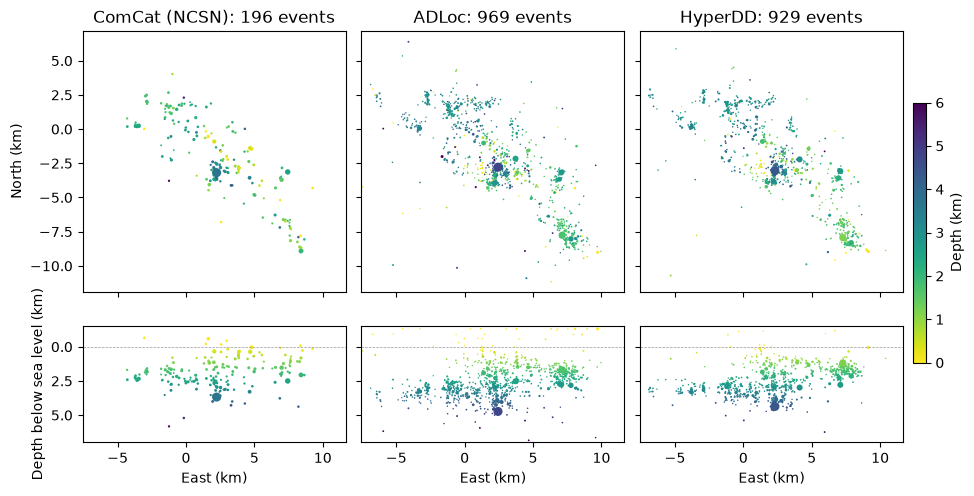

In [26]:
plot_catalogs({"ComCat (NCSN)": standard_catalog, "ADLoc": adloc_catalog, "HyperDD": hyperdd_catalog}, config, box)

### Magnitudes

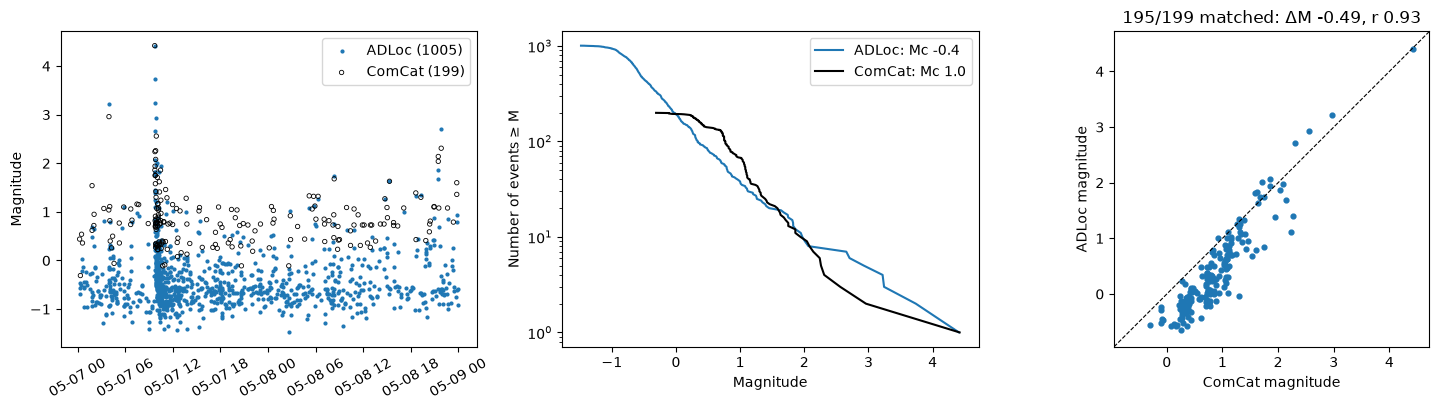

In [27]:
magnitude_pairs = plot_magnitudes(adloc_catalog, standard_catalog, config)

### Focal mechanisms

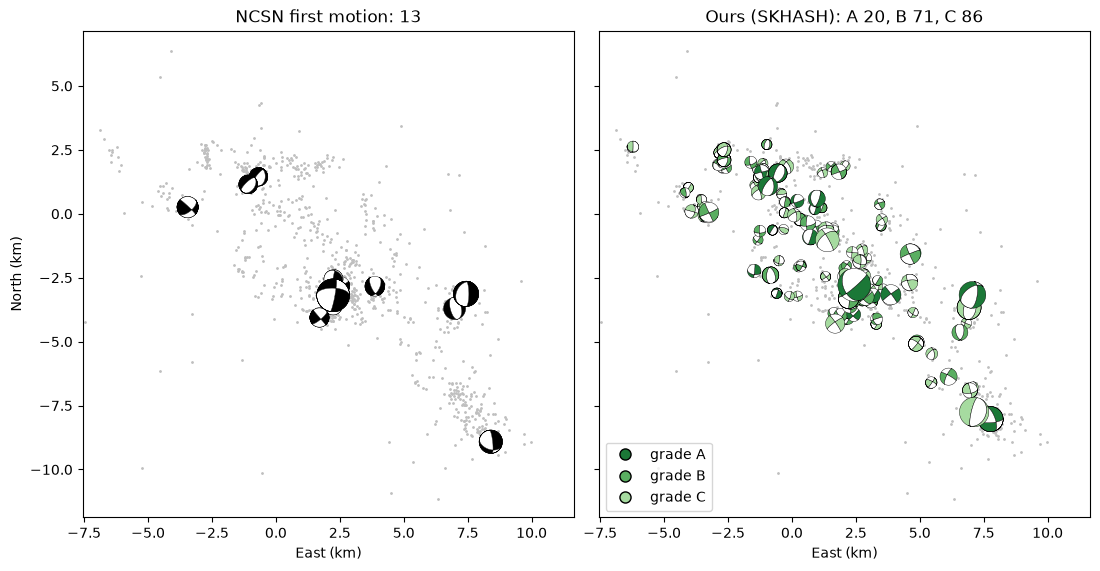

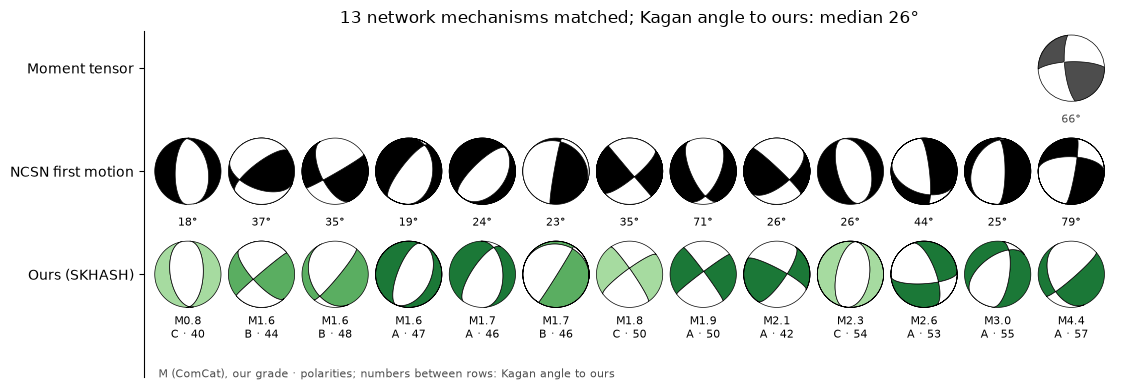

In [28]:
reference_mechanisms = download_mechanisms(config)
mechanism_pairs = plot_mechanisms(skhash_catalog, reference_mechanisms, adloc_catalog, config, box)